# Experimento espectral: STARLIGHT (modelo de mejor ajuste)

Experimento reproducible de clasificación binaria `temprana = 0.0` frente a `tardia = 1.0` usando exclusivamente el espectro modelado de STARLIGHT (`FLUX_FoV` de mejor ajuste, un canal) desde la caché `spectra_cache_starlight`, malla 3600–8900 Å. No se mezcla con cachés MPL-11 ni se compara punto a punto con `spectra_cache_starlight` (3600–9000 Å).

La cohorte y los splits provienen de `src.dataloader.multimodal`. La CNN 1D propaga la máscara espectral durante la reducción de resolución y hace pooling global enmascarado, de modo que el relleno con ceros fuera de cobertura no contribuya a la representación.

In [1]:
from __future__ import annotations

import copy
import json
import random
import sys
import time
from pathlib import Path
from typing import Any, Mapping

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, balanced_accuracy_score, f1_score
from torch import nn


def project_root(start: Path = Path.cwd()) -> Path:
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "src").is_dir() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("No se encontró la raíz del proyecto.")


ROOT = project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.dataloader.multimodal import build_dataloaders
from src.evaluate import evaluate_binary_classifier

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Proyecto: {ROOT}")
print(f"Dispositivo: {DEVICE}")

Proyecto: /home/albertor/Documents/deep_learning/repos/clasificacion-galaxias
Dispositivo: cuda


## Configuración e invariantes

- El split `data/processed/splits_seed42_obj-label_FoV.csv` es fijo: no se regenera dentro del experimento.
- La única modalidad activa es `spectrum`, desde la caché explícita `spectra_cache_starlight`.
- La selección de checkpoints usa solo validación; `test` se consulta una única vez para el modelo seleccionado.
- Se usa una salida logit por galaxia y `BCEWithLogitsLoss`.

In [2]:
CONFIG: dict[str, Any] = {
    "experiment_name": "espectros_starlight_cnn1d",
    "seed": 42,
    "data": {
        "project_root": ROOT,
        "manifest": "data/galaxy_manifest.csv",
        "splits": "data/processed/splits_seed42_obj-label_FoV.csv",
        "modalities": ["spectrum"],
        "spectrum": {
            "cache_dir": "data/processed/spectra/spectra_cache_starlight",
        },
    },
    "model": {
        "spectrum_embedding_dim": 128,
        "classifier_hidden_dim": 128,
        "dropout": 0.3,
    },
    "training": {
        "batch_size": 32,
        "num_workers": 0,
        "pin_memory": DEVICE.type == "cuda",
        "epochs": 50,
        "learning_rate": 1e-4,
        "weight_decay": 1e-4,
        "early_stopping_patience": 8,
    },
    "selection_metric": "roc_auc",
}

RUN_DIR = ROOT / "models" / "experiments" / CONFIG["experiment_name"]
CHECKPOINT_PATH = RUN_DIR / "best_model.pt"
RESULTS_PATH = RUN_DIR / "results.json"
CONFIG_PATH = RUN_DIR / "config.json"

In [3]:
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(CONFIG["seed"])
train_loader, validation_loader, test_loader = build_dataloaders(CONFIG)
loaders = {"train": train_loader, "validation": validation_loader, "test": test_loader}

for split_name, loader in loaders.items():
    labels = loader.dataset.frame["label"].value_counts()
    print(f"{split_name:10s} n={len(loader.dataset):5d}  temprana={labels.get('temprana', 0):5d}  tardia={labels.get('tardia', 0):5d}")

sample_batch = next(iter(train_loader))
for key, value in sample_batch.items():
    if isinstance(value, torch.Tensor):
        print(f"{key:16s} {tuple(value.shape)} {value.dtype}")
    else:
        print(f"{key:16s} {type(value).__name__}")

train      n= 6545  temprana= 2467  tardia= 4078
validation n= 1403  temprana=  529  tardia=  874
test       n= 1403  temprana=  528  tardia=  875
id               list
label            (32,) torch.float32
spectrum         (32, 1, 4096) torch.float32
spectrum_mask    (32, 4096) torch.bool


## Modelo: CNN 1D espectral

El baseline usa exclusivamente `spectrum` y `spectrum_mask`. Cada bloque convolucional reduce la resolución espectral por un factor de dos; la máscara se reduce en paralelo y se usa en el pooling global, por lo que las posiciones rellenadas fuera de cobertura no aportan flujo artificial al embedding.

In [4]:
import torch.nn.functional as F


class SpectrumEncoder(nn.Module):
    def __init__(self, input_channels: int, embedding_dim: int, dropout: float) -> None:
        super().__init__()
        channels = (input_channels, 32, 64, 128)
        self.blocks = nn.ModuleList(
            [
                nn.Sequential(
                    nn.Conv1d(in_channels, out_channels, kernel_size=5, stride=2, padding=2),
                    nn.GELU(),
                )
                for in_channels, out_channels in zip(channels[:-1], channels[1:])
            ]
        )
        self.projection = nn.Sequential(
            nn.Linear(channels[-1], embedding_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
        )

    @staticmethod
    def _downsample_mask(mask: torch.Tensor) -> torch.Tensor:
        return F.max_pool1d(mask.float().unsqueeze(1), kernel_size=5, stride=2, padding=2).squeeze(1).bool()

    def forward(self, spectrum: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        if spectrum.ndim != 3 or mask.shape != spectrum.shape[:1] + spectrum.shape[2:]:
            raise ValueError("Se esperaba spectrum=[B, C, L] y spectrum_mask=[B, L].")
        mask = mask.bool()
        for block in self.blocks:
            spectrum = block(spectrum)
            mask = self._downsample_mask(mask)
            spectrum = spectrum * mask.unsqueeze(1)
        weights = mask.unsqueeze(1).to(spectrum.dtype)
        pooled = (spectrum * weights).sum(dim=-1) / weights.sum(dim=-1).clamp_min(1.0)
        return self.projection(pooled)


class SpectrumClassifier(nn.Module):
    def __init__(
        self,
        spectrum_channels: int,
        spectrum_embedding_dim: int,
        classifier_hidden_dim: int,
        dropout: float,
    ) -> None:
        super().__init__()
        self.spectrum_encoder = SpectrumEncoder(spectrum_channels, spectrum_embedding_dim, dropout)
        self.classifier = nn.Sequential(
            nn.Linear(spectrum_embedding_dim, classifier_hidden_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(classifier_hidden_dim, 1),
        )

    def forward(self, batch: Mapping[str, Any]) -> torch.Tensor:
        spectrum_embedding = self.spectrum_encoder(batch["spectrum"], batch["spectrum_mask"])
        return self.classifier(spectrum_embedding).squeeze(1)


def build_model(config: Mapping[str, Any], batch: Mapping[str, Any]) -> nn.Module:
    model_config = config["model"]
    return SpectrumClassifier(
        spectrum_channels=batch["spectrum"].shape[1],
        spectrum_embedding_dim=int(model_config["spectrum_embedding_dim"]),
        classifier_hidden_dim=int(model_config["classifier_hidden_dim"]),
        dropout=float(model_config["dropout"]),
    )


model = build_model(CONFIG, sample_batch).to(DEVICE)
with torch.no_grad():
    batch_on_device = {
        key: value.to(DEVICE, non_blocking=True) if isinstance(value, torch.Tensor) else value
        for key, value in sample_batch.items()
    }
    logits = model(batch_on_device)
if logits.shape != sample_batch["label"].shape:
    raise ValueError(f"El modelo devolvió {tuple(logits.shape)}; se esperaba {tuple(sample_batch['label'].shape)}.")
assert torch.isfinite(logits).all()
print(model)
print(f"Forward de prueba: {tuple(logits.shape)}")

SpectrumClassifier(
  (spectrum_encoder): SpectrumEncoder(
    (blocks): ModuleList(
      (0): Sequential(
        (0): Conv1d(1, 32, kernel_size=(5,), stride=(2,), padding=(2,))
        (1): GELU(approximate='none')
      )
      (1): Sequential(
        (0): Conv1d(32, 64, kernel_size=(5,), stride=(2,), padding=(2,))
        (1): GELU(approximate='none')
      )
      (2): Sequential(
        (0): Conv1d(64, 128, kernel_size=(5,), stride=(2,), padding=(2,))
        (1): GELU(approximate='none')
      )
    )
    (projection): Sequential(
      (0): Linear(in_features=128, out_features=128, bias=True)
      (1): ReLU(inplace=True)
      (2): Dropout(p=0.3, inplace=False)
    )
  )
  (classifier): Sequential(
    (0): Linear(in_features=128, out_features=128, bias=True)
    (1): ReLU(inplace=True)
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=1, bias=True)
  )
)
Forward de prueba: (32,)


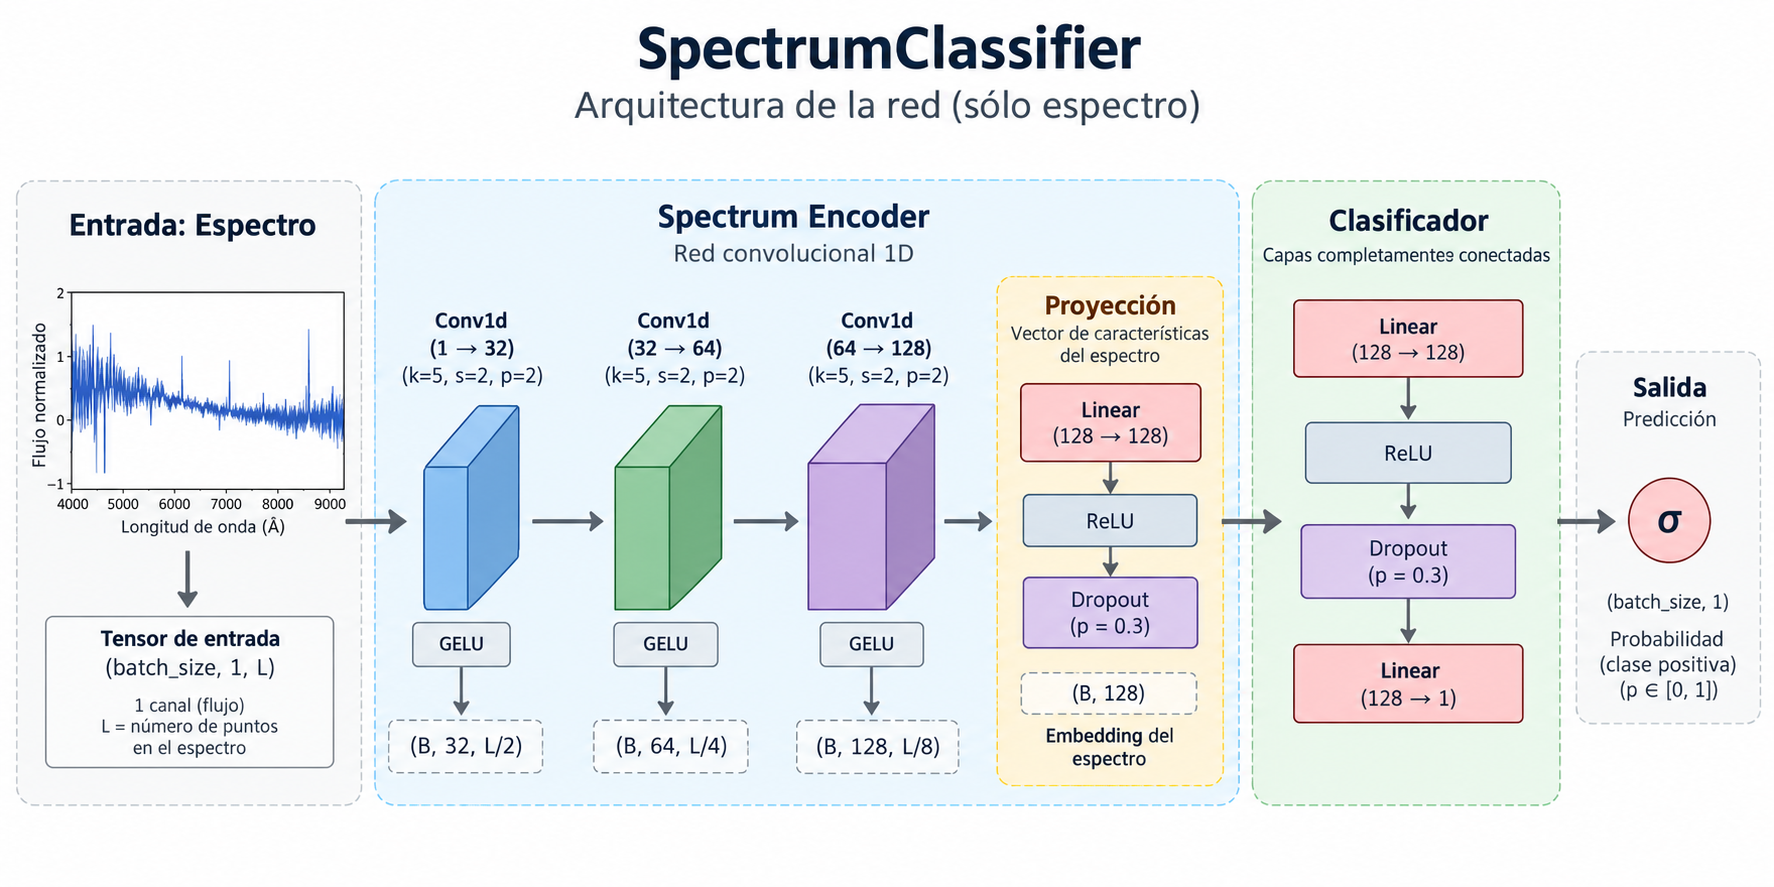

In [5]:
def move_batch_to_device(batch: Mapping[str, Any], device: torch.device) -> dict[str, Any]:
    return {
        key: value.to(device, non_blocking=True) if isinstance(value, torch.Tensor) else value
        for key, value in batch.items()
    }


def logits_from_model(model: nn.Module, batch: Mapping[str, Any]) -> torch.Tensor:
    logits = model(batch)
    expected_shape = batch["label"].shape
    if logits.shape != expected_shape:
        raise ValueError(f"El modelo devolvió {tuple(logits.shape)}; se esperaba {tuple(expected_shape)}.")
    return logits


def train_epoch(
    model: nn.Module,
    loader: torch.utils.data.DataLoader,
    optimizer: torch.optim.Optimizer,
    criterion: nn.Module,
    device: torch.device,
) -> float:
    model.train()
    total_loss = 0.0
    for batch in loader:
        batch = move_batch_to_device(batch, device)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(logits_from_model(model, batch), batch["label"])
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * batch["label"].numel()
    return total_loss / len(loader.dataset)


@torch.no_grad()
def evaluate_epoch(
    model: nn.Module,
    loader: torch.utils.data.DataLoader,
    criterion: nn.Module,
    device: torch.device,
) -> tuple[float, np.ndarray, np.ndarray, np.ndarray]:
    model.eval()
    total_loss = 0.0
    all_true, all_pred, all_proba = [], [], []
    for batch in loader:
        batch = move_batch_to_device(batch, device)
        logits = logits_from_model(model, batch)
        total_loss += criterion(logits, batch["label"]).item() * batch["label"].numel()
        probabilities = torch.sigmoid(logits)
        all_true.append(batch["label"].cpu().numpy())
        all_pred.append((probabilities >= 0.5).to(torch.int64).cpu().numpy())
        all_proba.append(probabilities.cpu().numpy())
    return (
        total_loss / len(loader.dataset),
        np.concatenate(all_true),
        np.concatenate(all_pred),
        np.concatenate(all_proba),
    )

In [6]:
def fit(
    model: nn.Module,
    train_loader: torch.utils.data.DataLoader,
    validation_loader: torch.utils.data.DataLoader,
    config: Mapping[str, Any],
    device: torch.device,
    checkpoint_path: Path,
) -> pd.DataFrame:
    training_config = config["training"]
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=training_config["learning_rate"],
        weight_decay=training_config["weight_decay"],
    )
    history: list[dict[str, float]] = []
    best_score = float("-inf")
    best_state: dict[str, torch.Tensor] | None = None
    epochs_without_improvement = 0

    for epoch in range(1, training_config["epochs"] + 1):
        started_at = time.perf_counter()
        train_loss = train_epoch(model, train_loader, optimizer, criterion, device)
        validation_loss, y_true, y_pred, y_proba = evaluate_epoch(
            model, validation_loader, criterion, device
        )
        metrics = evaluate_binary_classifier(y_true, y_pred, y_proba)
        score = float(metrics[config["selection_metric"]])
        history.append(
            {
                "epoch": epoch,
                "train_loss": train_loss,
                "validation_loss": validation_loss,
                "validation_accuracy": float(metrics["accuracy"]),
                "validation_balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
                "validation_f1": f1_score(y_true, y_pred, zero_division=0),
                "validation_roc_auc": float(metrics["roc_auc"]),
                "seconds": time.perf_counter() - started_at,
            }
        )
        print(
            f"[{epoch:02d}/{training_config['epochs']}] "
            f"train_loss={train_loss:.4f} val_loss={validation_loss:.4f} "
            f"val_auc={metrics['roc_auc']:.4f}"
        )

        if score > best_score:
            best_score = score
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= training_config["early_stopping_patience"]:
                print("Early stopping por validación.")
                break

    if best_state is None:
        raise RuntimeError("No se obtuvo un checkpoint de validación.")
    checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
    model.load_state_dict(best_state)
    torch.save({"model_state_dict": best_state, "config": dict(config)}, checkpoint_path)
    return pd.DataFrame(history)


# Para entrenar después de implementar build_model:
model = build_model(CONFIG, sample_batch).to(DEVICE)
history = fit(model, train_loader, validation_loader, CONFIG, DEVICE, CHECKPOINT_PATH)

[01/50] train_loss=0.6694 val_loss=0.6623 val_auc=0.5359
[02/50] train_loss=0.6638 val_loss=0.6624 val_auc=0.5539
[03/50] train_loss=0.6625 val_loss=0.6620 val_auc=0.5838
[04/50] train_loss=0.6628 val_loss=0.6623 val_auc=0.6588
[05/50] train_loss=0.6612 val_loss=0.6577 val_auc=0.7756
[06/50] train_loss=0.5919 val_loss=0.4977 val_auc=0.8271
[07/50] train_loss=0.4768 val_loss=0.4835 val_auc=0.8387
[08/50] train_loss=0.4759 val_loss=0.4823 val_auc=0.8387
[09/50] train_loss=0.4723 val_loss=0.4845 val_auc=0.8393
[10/50] train_loss=0.4693 val_loss=0.4827 val_auc=0.8406
[11/50] train_loss=0.4683 val_loss=0.4811 val_auc=0.8406
[12/50] train_loss=0.4712 val_loss=0.4801 val_auc=0.8406
[13/50] train_loss=0.4690 val_loss=0.4810 val_auc=0.8406
[14/50] train_loss=0.4666 val_loss=0.4794 val_auc=0.8424
[15/50] train_loss=0.4680 val_loss=0.4784 val_auc=0.8423
[16/50] train_loss=0.4661 val_loss=0.4788 val_auc=0.8425
[17/50] train_loss=0.4646 val_loss=0.4789 val_auc=0.8433
[18/50] train_loss=0.4647 val_l

## Evaluación final y persistencia

Ejecute esta sección solo después de decidir la arquitectura e hiperparámetros usando validación. El split de `test` no participa en selección, calibración ni early stopping.

test_loss=0.4515  test_accuracy=0.7890  test_auc=0.8642
              precision    recall  f1-score      support
0.0            0.763636  0.636364  0.694215   528.000000
1.0            0.800623  0.881143  0.838955   875.000000
accuracy       0.789024  0.789024  0.789024     0.789024
macro avg      0.782130  0.758753  0.766585  1403.000000
weighted avg   0.786704  0.789024  0.784484  1403.000000


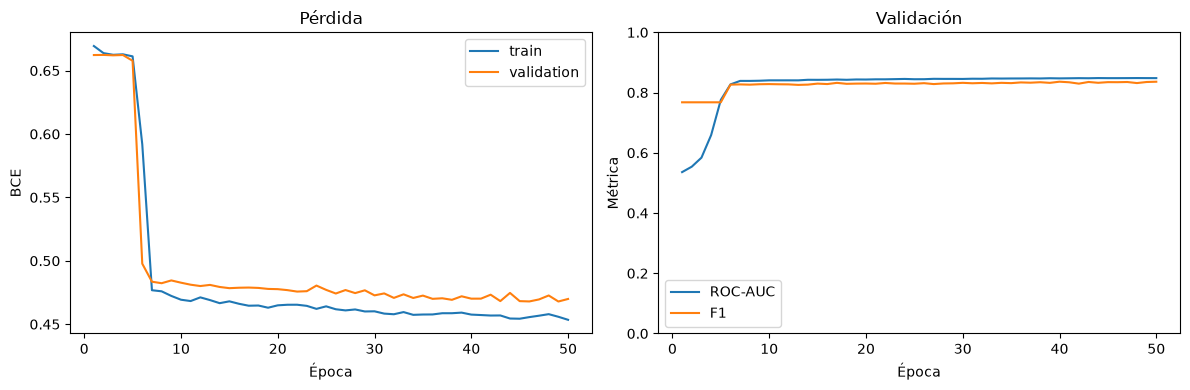

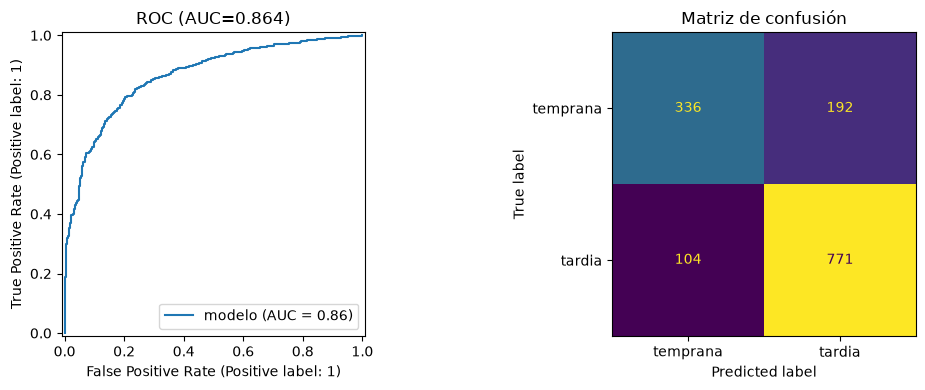

In [7]:
def plot_history(history: pd.DataFrame) -> None:
    figure, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["epoch"], history["train_loss"], label="train")
    axes[0].plot(history["epoch"], history["validation_loss"], label="validation")
    axes[0].set(title="Pérdida", xlabel="Época", ylabel="BCE")
    axes[0].legend()
    axes[1].plot(history["epoch"], history["validation_roc_auc"], label="ROC-AUC")
    axes[1].plot(history["epoch"], history["validation_f1"], label="F1")
    axes[1].set(title="Validación", xlabel="Época", ylabel="Métrica", ylim=(0, 1))
    axes[1].legend()
    figure.tight_layout()


def plot_binary_evaluation(y_true: np.ndarray, y_proba: np.ndarray, metrics: Mapping[str, Any]) -> None:
    figure, axes = plt.subplots(1, 2, figsize=(11, 4))
    RocCurveDisplay.from_predictions(y_true, y_proba, ax=axes[0], name="modelo")
    axes[0].set_title(f"ROC (AUC={metrics['roc_auc']:.3f})")
    ConfusionMatrixDisplay(
        confusion_matrix=metrics["confusion_matrix"],
        display_labels=["temprana", "tardia"],
    ).plot(ax=axes[1], colorbar=False)
    axes[1].set_title("Matriz de confusión")
    figure.tight_layout()


def to_jsonable(value: Any) -> Any:
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, Mapping):
        return {str(key): to_jsonable(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [to_jsonable(item) for item in value]
    return value


def save_run_artifacts(
    config: Mapping[str, Any], history: pd.DataFrame, test_metrics: Mapping[str, Any]
) -> None:
    RUN_DIR.mkdir(parents=True, exist_ok=True)
    with CONFIG_PATH.open("w", encoding="utf-8") as file:
        json.dump(to_jsonable(config), file, indent=2)
    history.to_csv(RUN_DIR / "history.csv", index=False)
    with RESULTS_PATH.open("w", encoding="utf-8") as file:
        json.dump(to_jsonable(test_metrics), file, indent=2)


# Después de seleccionar el experimento con validación:
criterion = nn.BCEWithLogitsLoss()
test_loss, y_test, y_test_pred, y_test_proba = evaluate_epoch(model, test_loader, criterion, DEVICE)
test_metrics = evaluate_binary_classifier(y_test, y_test_pred, y_test_proba)
print(f"test_loss={test_loss:.4f}  test_accuracy={test_metrics['accuracy']:.4f}  test_auc={test_metrics['roc_auc']:.4f}")
print(pd.DataFrame(test_metrics["report"]).T)
plot_history(history)
plot_binary_evaluation(y_test, y_test_proba, test_metrics)
save_run_artifacts(CONFIG, history, {"test_loss": test_loss, **test_metrics})

In [8]:
# Guarda
RUN_DIR.mkdir(parents=True, exist_ok=True)

experiment_data = {
    "model_state_dict": {
        name: tensor.detach().cpu()
        for name, tensor in model.state_dict().items()
    },
    "config": to_jsonable(CONFIG),
    "device": str(DEVICE),
    "parameter_count": sum(parameter.numel() for parameter in model.parameters()),
    "history": history.to_dict(orient="records"),
    "test_metrics": to_jsonable(
        {"test_loss": test_loss, **test_metrics}
    ),
}

checkpoint_path = RUN_DIR / "experiment_checkpoint.pt"
torch.save(experiment_data, checkpoint_path)

with (RUN_DIR / "config.json").open("w", encoding="utf-8") as file:
    json.dump(to_jsonable(CONFIG), file, indent=2)

history.to_csv(RUN_DIR / "history.csv", index=False)

with (RUN_DIR / "test_metrics.json").open("w", encoding="utf-8") as file:
    json.dump(
        to_jsonable({"test_loss": test_loss, **test_metrics}),
        file,
        indent=2,
    )

print(f"Modelo y resultados guardados en: {RUN_DIR}")
print(f"Checkpoint: {checkpoint_path}")

Modelo y resultados guardados en: /home/albertor/Documents/deep_learning/repos/clasificacion-galaxias/models/experiments/espectros_starlight_cnn1d
Checkpoint: /home/albertor/Documents/deep_learning/repos/clasificacion-galaxias/models/experiments/espectros_starlight_cnn1d/experiment_checkpoint.pt
